# Rôle 1 : analyse exploratoire des projets

Objectif : connaître les 2 000 projets de `data/processed/projets.csv` avant de construire les modèles de rentabilité (régression) et de risque (classification).

1. Chargement : taille et types
2. Qualité : valeurs manquantes, doublons, valeurs extrêmes
3. Les deux cibles (projets terminés)
4. Variables numériques
5. Variables catégorielles
6. Liens entre variables et cibles, corrélations
7. Les 40 anomalies fabriquées
8. Conséquences pour le prétraitement

**À garder en tête.** Les projets sont réels (Banque mondiale, licence CC BY 4.0), mais `rentabilite` et `risque` sont **simulées** par une formule avec du bruit (voir `data/README.md`). Elles ne sont connues que pour les **1 500 projets terminés** ; les 500 projets en cours sont ceux que l'agent devra évaluer.

Cette analyse est **descriptive** : on ne règle ici aucun paramètre appris sur les données. La séparation entraînement / validation / test (tâche 3) se fait juste après, avant tout prétraitement.

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

logging.basicConfig(level=logging.INFO, format="%(message)s")
journal = logging.getLogger("exploration")

RACINE = Path.cwd().resolve().parents[1]
DONNEES = RACINE / "data" / "processed"
FIGURES = RACINE / "reports" / "role1" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120)


def enregistrer(nom: str) -> None:
    """Enregistre la figure courante dans reports/role1/figures/."""
    plt.tight_layout()
    plt.savefig(FIGURES / f"{nom}.png", dpi=120)

## 1. Chargement : taille et types

In [2]:
projets = pd.read_csv(DONNEES / "projets.csv")
print(projets.shape[0], "projets,", projets.shape[1], "colonnes")
print(projets["statut"].value_counts().to_string())
projets.head()

2000 projets, 12 colonnes
statut
termine     1500
en_cours     500


,id_projet,nom,secteur,pays,region,cout_total,duree_mois,annee_approbation,type_financement,statut,rentabilite,risque
0,P000001,West Africa Pilot Community-based Natural Reso...,Gouvernance,Africa,Afrique,13.19,106,1995,Autre,termine,5.5,eleve
1,P000034,INFRASTRUCTURE REHAB,Transport,Angola,Afrique de l'Est et australe,23.20,92,1991,IDA,termine,6.9,faible
2,P000044,Financial Institutions modernization project,Finance,Angola,Afrique de l'Est et australe,21.00,116,1992,IDA,termine,4.1,moyen
3,P000103,EDUCATION DEVELOPMENT PROJECT,Éducation,Benin,Afrique de l'Ouest et centrale,22.90,91,1994,IDA,termine,7.2,moyen
4,P000237,AGRI-BUSINESS PROMOT,Industrie et commerce,Burundi,Afrique de l'Est et australe,3.10,79,1992,IDA,termine,9.4,faible


In [3]:
projets.dtypes.to_frame("type")

,type
id_projet,str
nom,str
secteur,str
pays,str
region,str
cout_total,float64
duree_mois,int64
annee_approbation,int64
type_financement,str
statut,str


2 000 projets et 12 colonnes : 1 500 terminés, 500 en cours. Les types sont corrects à la lecture (coût en nombre décimal, durée et année en entiers, le reste en texte).

Rôle de chaque colonne pour le modèle :

| Colonne | Rôle |
|---|---|
| `id_projet`, `nom` | identifiants : **exclus** des entrées (ils n'apportent rien et pourraient faire apprendre par cœur) |
| `secteur`, `pays`, `region`, `type_financement` | entrées catégorielles |
| `cout_total`, `duree_mois`, `annee_approbation` | entrées numériques |
| `statut` | sert à séparer terminés et en cours, **pas** une entrée |
| `rentabilite`, `risque` | **cibles** |

## 2. Qualité des données

In [4]:
manquants = projets.isna().sum().to_frame("manquants")
manquants["manquants_terminés"] = projets[projets["statut"] == "termine"].isna().sum()
manquants

,manquants,manquants_terminés
id_projet,0,0
nom,0,0
secteur,0,0
pays,0,0
region,0,0
cout_total,0,0
duree_mois,0,0
annee_approbation,0,0
type_financement,0,0
statut,0,0


Les seules valeurs manquantes sont les cibles des 500 projets en cours : c'est attendu, ce sont les projets à évaluer. Chez les projets terminés, aucune valeur ne manque. `predict` devra quand même supporter une valeur manquante (exigence du contrat) : on gardera un `SimpleImputer` dans le pipeline.

In [5]:
print("Lignes entièrement identiques :", projets.duplicated().sum())
print("Identifiants en double :", projets["id_projet"].duplicated().sum())
print("Lignes identiques hors identifiant :", projets.drop(columns="id_projet").duplicated().sum())
noms_doubles = projets[projets["nom"].duplicated(keep=False)].sort_values("nom")
print("Noms portés par plusieurs projets :", noms_doubles["nom"].nunique())
noms_doubles[["id_projet", "nom", "pays", "annee_approbation", "cout_total", "statut"]]

Lignes entièrement identiques : 0
Identifiants en double : 0
Lignes identiques hors identifiant : 0
Noms portés par plusieurs projets : 9


,id_projet,nom,pays,annee_approbation,cout_total,statut
1094,P145586,China Partnership for Market Readiness,China,2014,8.60,termine
1407,P166983,China Partnership for Market Readiness,China,2019,2.00,termine
324,P050474,Education Reform Project,Russian Federation,2001,71.10,termine
369,P057959,Education Reform Project,Azerbaijan,1999,5.50,termine
397,P065035,Gansu and Xinjiang Pastoral Development Project,China,2003,99.10,termine
512,P077615,Gansu and Xinjiang Pastoral Development Project,China,2003,12.49,termine
422,P069892,Local Empowerment and Environmental Management...,Nigeria,2003,81.17,termine
454,P071817,Local Empowerment and Environmental Management...,Nigeria,2003,9.81,termine
1446,P168608,Resilient Urban Sierra Leone Project,Sierra Leone,2021,56.73,en_cours
1563,P173676,Resilient Urban Sierra Leone Project,Sierra Leone,2021,289.19,en_cours


Aucun doublon : chaque identifiant est unique et aucune ligne n'en répète une autre. Neuf noms reviennent deux fois : soit le même intitulé dans deux pays (« Education Reform Project » en Russie et en Azerbaïdjan), soit deux opérations distinctes d'un même programme (même pays, identifiants différents, coûts différents). Ce sont des projets distincts, on les garde.

In [6]:
projets.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
cout_total,2000.0,260.09,1287.03,1.0,17.68,57.5,183.92,37706.85
duree_mois,2000.0,66.58,31.31,1.0,47.00,68.0,86.00,175.00
annee_approbation,2000.0,2011.28,10.10,1987.0,2004.00,2012.5,2020.00,2026.00
rentabilite,1500.0,8.43,5.09,-58.5,6.30,8.4,10.42,58.50


Le coût va de 1 à près de 38 000 millions de dollars, avec une moyenne (260) très au-dessus de la médiane : la distribution est très étalée vers la droite. La durée va de 1 à 175 mois : des durées de 1 à 3 mois sont suspectes (le filtre de préparation gardait 6 mois au moins), ce sont des anomalies fabriquées (partie 7). La rentabilité va de −58,5 % à +58,5 % alors que la moitié des projets est entre 6,3 % et 10,4 % : là encore, des anomalies.

## 3. Les deux cibles (projets terminés seulement)

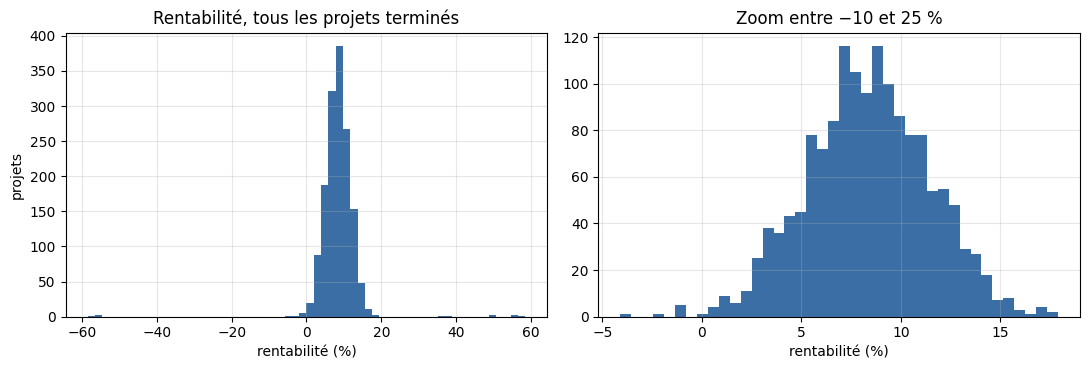

count    1500.00
mean        8.43
std         5.09
min       -58.50
25%         6.30
50%         8.40
75%        10.42
max        58.50
Projets hors de [−10 ; 25] % : 10


In [7]:
termines = projets[projets["statut"] == "termine"].copy()
en_cours = projets[projets["statut"] == "en_cours"].copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(termines["rentabilite"], bins=60, color="#3b6ea5")
axes[0].set(title="Rentabilité, tous les projets terminés", xlabel="rentabilité (%)", ylabel="projets")
centre = termines["rentabilite"].between(-10, 25)
axes[1].hist(termines.loc[centre, "rentabilite"], bins=40, color="#3b6ea5")
axes[1].set(title="Zoom entre −10 et 25 %", xlabel="rentabilité (%)")
enregistrer("cible_rentabilite")
plt.show()
print(termines["rentabilite"].describe().round(2).to_string())
print("Projets hors de [−10 ; 25] % :", (~centre).sum())

La rentabilité a une forme en cloche centrée vers 8,4 % (écart-type d'environ 3 points une fois les anomalies écartées), comme le prévoit la formule de simulation. Une dizaine de projets sont très loin du centre (au-delà de ±35 %) : ce sont les anomalies `rentabilite_extreme`. Elles sont peu nombreuses mais, au carré, elles pèsent lourd dans une régression par moindres carrés : il faudra les retirer de l'entraînement ou vérifier que le modèle y résiste.

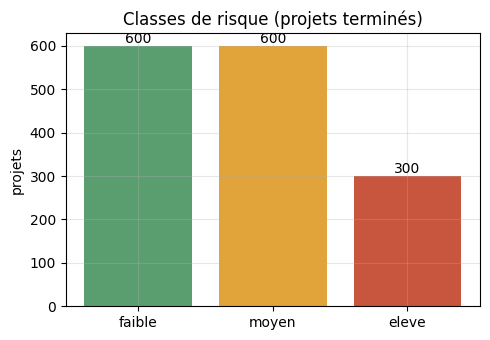

,part
risque,
faible,0.4
moyen,0.4
eleve,0.2


In [8]:
ordre_risque = ["faible", "moyen", "eleve"]
comptes = termines["risque"].value_counts().reindex(ordre_risque)
fig, ax = plt.subplots(figsize=(5, 3.5))
barres = ax.bar(comptes.index, comptes.values, color=["#5a9e6f", "#e0a43a", "#c8553d"])
ax.bar_label(barres)
ax.set(title="Classes de risque (projets terminés)", ylabel="projets")
enregistrer("cible_risque")
plt.show()
(comptes / comptes.sum()).round(2).to_frame("part")

Les classes sont déséquilibrées par construction : 40 % `faible`, 40 % `moyen`, 20 % `eleve`. Un modèle qui répond toujours la classe la plus fréquente a déjà 40 % de bonnes réponses : c'est la référence à battre. Comme la classe `eleve` est la plus rare et la plus importante pour l'agent (`proba_risque`), on suivra le **F1 macro** en plus de l'exactitude, et la séparation entraînement / validation / test sera **stratifiée** sur le risque.

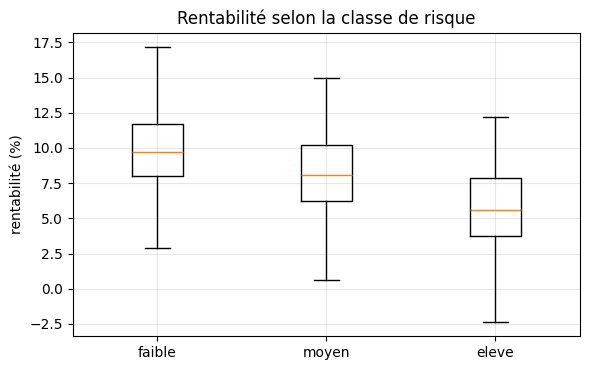

,médiane (%)
risque,
faible,9.7
moyen,8.1
eleve,5.6


In [9]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.boxplot([termines.loc[termines["risque"] == r, "rentabilite"] for r in ordre_risque],
           tick_labels=ordre_risque, showfliers=False)
ax.set(title="Rentabilité selon la classe de risque", ylabel="rentabilité (%)")
enregistrer("rentabilite_par_risque")
plt.show()
termines.groupby("risque")["rentabilite"].median().reindex(ordre_risque).round(1).to_frame("médiane (%)")

Les deux cibles sont liées : plus le risque est élevé, plus la rentabilité est basse (médiane de 9,7 % en `faible`, 8,1 % en `moyen`, 5,6 % en `eleve`). C'est voulu par la formule (le score de risque contient −0,6 × la rentabilité). On ne pourra **pas** utiliser la rentabilité comme entrée du modèle de risque : elle est inconnue pour les projets en cours.

## 4. Variables numériques

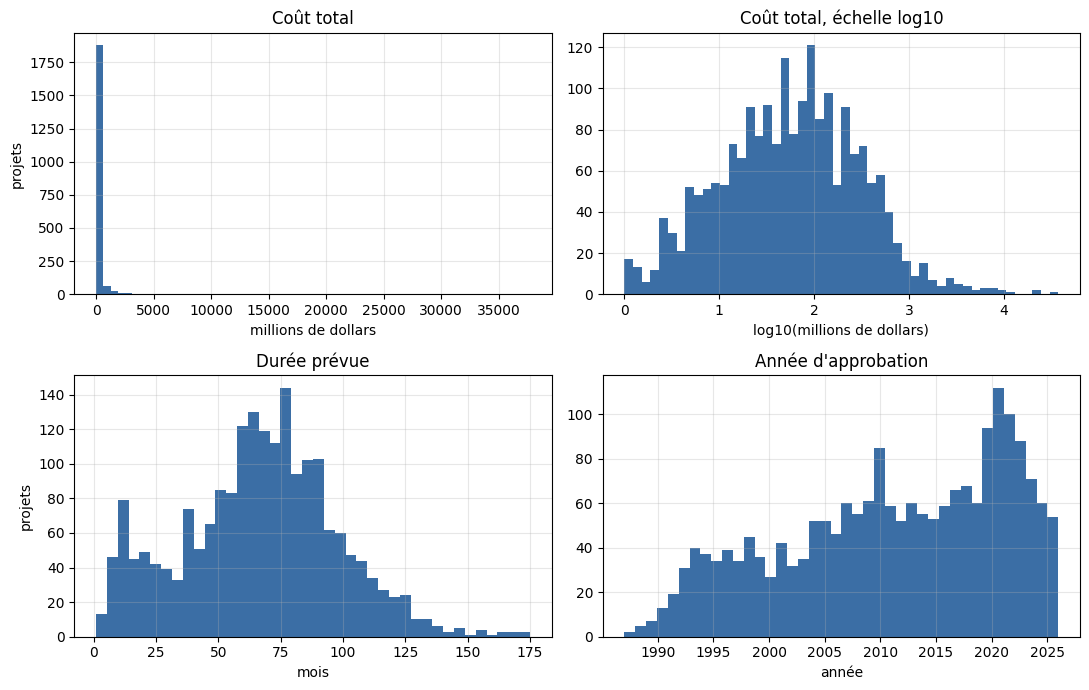

Asymétrie du coût : 18.5 ; après log10 : 0.06


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(projets["cout_total"], bins=60, color="#3b6ea5")
axes[0, 0].set(title="Coût total", xlabel="millions de dollars", ylabel="projets")
axes[0, 1].hist(np.log10(projets["cout_total"]), bins=50, color="#3b6ea5")
axes[0, 1].set(title="Coût total, échelle log10", xlabel="log10(millions de dollars)")
axes[1, 0].hist(projets["duree_mois"], bins=40, color="#3b6ea5")
axes[1, 0].set(title="Durée prévue", xlabel="mois", ylabel="projets")
axes[1, 1].hist(projets["annee_approbation"], bins=40, color="#3b6ea5")
axes[1, 1].set(title="Année d'approbation", xlabel="année")
enregistrer("variables_numeriques")
plt.show()
print("Asymétrie du coût :", round(projets["cout_total"].skew(), 1),
      "; après log10 :", round(np.log10(projets["cout_total"]).skew(), 2))

Le coût est extrêmement asymétrique (quelques projets géants écrasent l'histogramme) ; en échelle logarithmique il devient à peu près symétrique. On passera donc le coût au **log10** avant de le standardiser, ce qui correspond d'ailleurs à la formule de simulation (`z_cout` est calculé sur le log10). La durée est étalée entre 6 et 180 mois avec quelques valeurs à 1 à 3 mois (anomalies). Les années vont de 1987 à 2026, avec plus de projets récents.

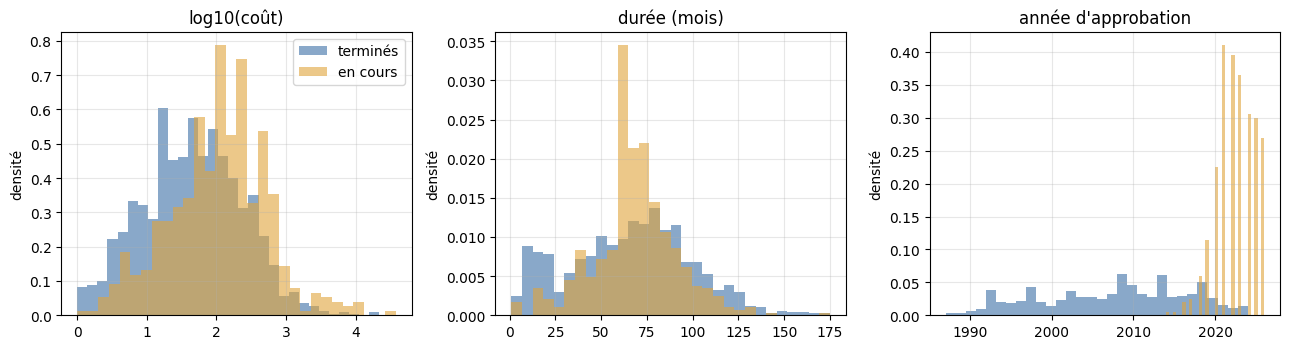

,cout_total,duree_mois,annee_approbation
statut,,,
en_cours,106.750,67.0,2022.0
termine,46.115,68.0,2009.0


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (colonne, transformer, titre) in zip(axes, [
    ("cout_total", np.log10, "log10(coût)"),
    ("duree_mois", None, "durée (mois)"),
    ("annee_approbation", None, "année d'approbation"),
]):
    for groupe, couleur in [(termines, "#3b6ea5"), (en_cours, "#e0a43a")]:
        valeurs = groupe[colonne] if transformer is None else transformer(groupe[colonne])
        ax.hist(valeurs, bins=30, alpha=0.6, density=True, color=couleur)
    ax.set(title=titre, ylabel="densité")
axes[0].legend(["terminés", "en cours"])
enregistrer("termines_contre_en_cours")
plt.show()
projets.groupby("statut")[["cout_total", "duree_mois", "annee_approbation"]].median()

Point important : les projets en cours ne ressemblent pas tout à fait aux projets terminés. Ils sont **plus récents** (médiane 2022 contre 2009, ce qui est logique) et **plus chers** (médiane 107 contre 46 millions). Le modèle appris sur les projets terminés devra donc prédire en partie hors de ce qu'il a vu (années après 2020 surtout). La formule de simulation n'utilise pas l'année, donc ce décalage ne devrait pas trop nuire ici, mais c'est une limite à écrire dans le rapport.

## 5. Variables catégorielles

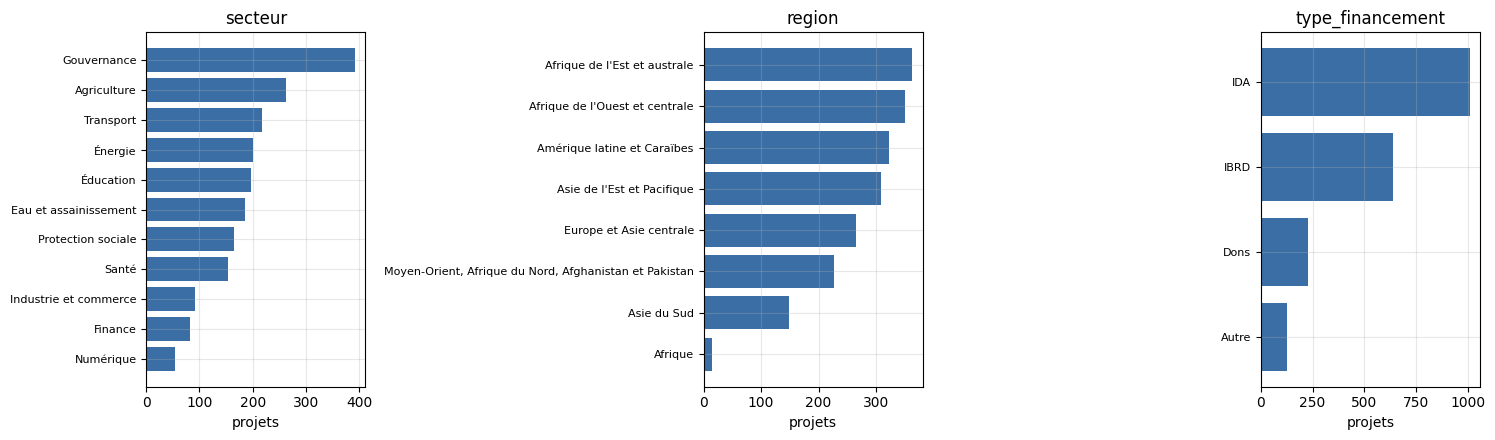

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, colonne in zip(axes, ["secteur", "region", "type_financement"]):
    comptes = projets[colonne].value_counts().sort_values()
    ax.barh(comptes.index, comptes.values, color="#3b6ea5")
    ax.set(title=colonne, xlabel="projets")
    ax.tick_params(axis="y", labelsize=8)
enregistrer("variables_categorielles")
plt.show()

11 secteurs, très inégaux : la gouvernance compte près de 400 projets, le numérique à peine plus de 50. 8 régions, dont une catégorie `Afrique` de 15 projets régionaux (plusieurs pays). Le financement IDA (pays les plus pauvres) domine, devant IBRD, les dons et `Autre`. Toutes les catégories ont assez de projets pour être encodées en indicatrices (`OneHotEncoder`).

Pays différents : 158
Pays avec moins de 5 projets : 42
Pays avec un seul projet : 9
Pays présents en cours mais jamais parmi les terminés : 3 ['Micronesia, Federated States of', 'St Maarten', 'Suriname']


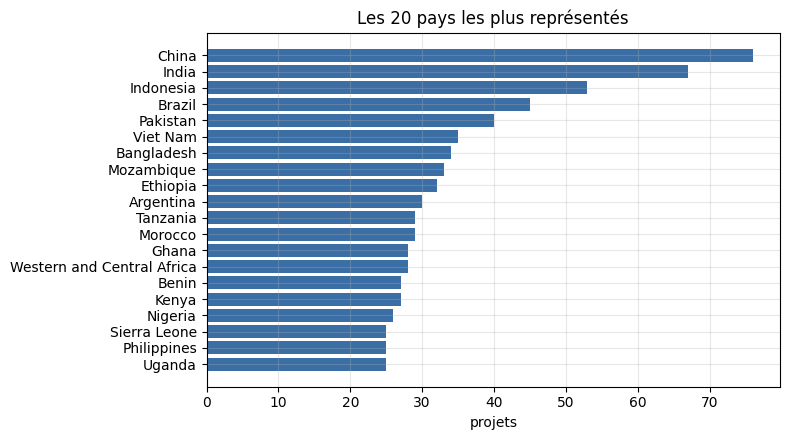

In [13]:
par_pays = projets["pays"].value_counts()
print("Pays différents :", par_pays.size)
print("Pays avec moins de 5 projets :", (par_pays < 5).sum())
print("Pays avec un seul projet :", (par_pays == 1).sum())
pays_en_cours_inconnus = set(en_cours["pays"]) - set(termines["pays"])
print("Pays présents en cours mais jamais parmi les terminés :", len(pays_en_cours_inconnus), sorted(pays_en_cours_inconnus))

fig, ax = plt.subplots(figsize=(8, 4.5))
top = par_pays.head(20).sort_values()
ax.barh(top.index, top.values, color="#3b6ea5")
ax.set(title="Les 20 pays les plus représentés", xlabel="projets")
enregistrer("pays_top20")
plt.show()

Le pays a 158 valeurs, dont beaucoup très rares (un ou deux projets). Certains pays des projets en cours n'apparaissent jamais parmi les projets terminés : c'est exactement le cas de la « catégorie jamais vue » du contrat. D'où `OneHotEncoder(handle_unknown="ignore")` : un pays inconnu donne une ligne d'indicatrices toutes à zéro, et le modèle s'appuie alors sur la région, le secteur et les chiffres. La région, plus grossière, sert de filet de sécurité.

## 6. Liens avec les cibles et corrélations

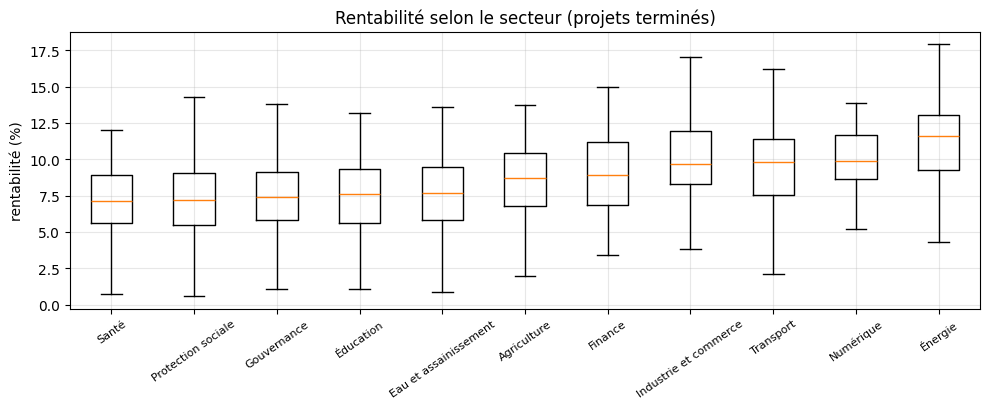

In [14]:
ordre = termines.groupby("secteur")["rentabilite"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.boxplot([termines.loc[termines["secteur"] == s, "rentabilite"] for s in ordre],
           tick_labels=ordre, showfliers=False)
ax.set(title="Rentabilité selon le secteur (projets terminés)", ylabel="rentabilité (%)")
ax.tick_params(axis="x", rotation=35, labelsize=8)
enregistrer("rentabilite_par_secteur")
plt.show()

Le secteur compte beaucoup : l'énergie est nettement au-dessus (médiane 11,6 %), la santé, la protection sociale et la gouvernance en dessous (environ 7 %). On retrouve à peu près l'ordre des effets de la formule de simulation. Le numérique a une médiane élevée (9,9 %) mais une moyenne plus basse (7,8 %), tirée par quelques valeurs extrêmes : avec seulement une quarantaine de projets terminés, son effet sera estimé avec beaucoup d'incertitude.

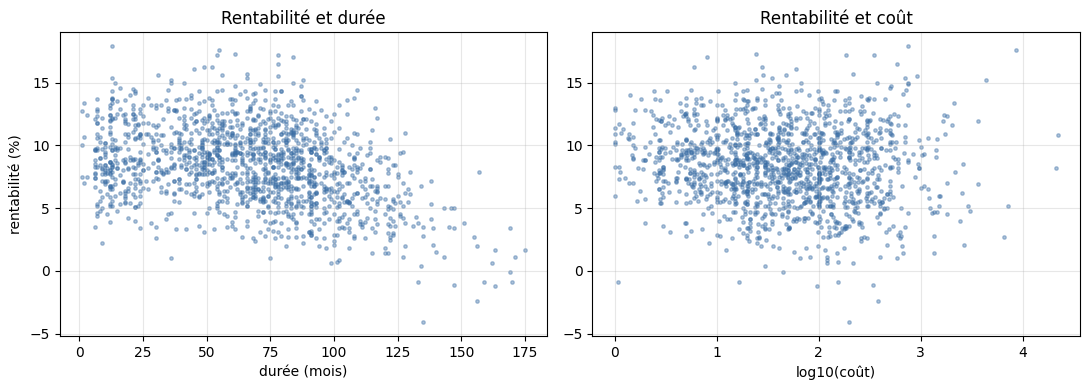

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
normaux = termines[termines["rentabilite"].between(-10, 25)]
axes[0].scatter(normaux["duree_mois"], normaux["rentabilite"], s=6, alpha=0.4, color="#3b6ea5")
axes[0].set(title="Rentabilité et durée", xlabel="durée (mois)", ylabel="rentabilité (%)")
axes[1].scatter(np.log10(normaux["cout_total"]), normaux["rentabilite"], s=6, alpha=0.4, color="#3b6ea5")
axes[1].set(title="Rentabilité et coût", xlabel="log10(coût)")
enregistrer("rentabilite_duree_cout")
plt.show()

La rentabilité baisse avec la durée, et la baisse s'accélère pour les projets très longs (nuage en arc) : c'est le terme en `z_duree²` de la formule. Un modèle linéaire sur la durée seule ne captera pas cette courbure ; un modèle à arbres (forêt, boosting) ou un terme au carré le pourrait. Le lien avec le coût est faible à l'œil, car il change de signe selon le secteur (négatif en général, positif pour l'énergie et le transport) : une interaction qu'un modèle linéaire simple ne voit pas.

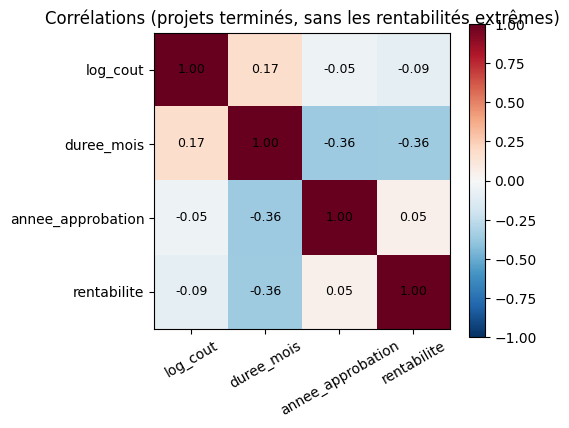

In [16]:
numeriques = termines.assign(log_cout=np.log10(termines["cout_total"]))[
    ["log_cout", "duree_mois", "annee_approbation", "rentabilite"]]
numeriques = numeriques[termines["rentabilite"].between(-10, 25)]
correlations = numeriques.corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations)), correlations.columns, rotation=30)
ax.set_yticks(range(len(correlations)), correlations.columns)
for i in range(len(correlations)):
    for j in range(len(correlations)):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.grid(False)
fig.colorbar(image)
ax.set_title("Corrélations (projets terminés, sans les rentabilités extrêmes)")
enregistrer("correlations")
plt.show()

Une fois les rentabilités extrêmes écartées, la durée est la variable numérique la plus liée à la rentabilité (corrélation −0,36) ; le coût (−0,09) et l'année (0,05) le sont très peu. Cela ne veut pas dire que le coût est inutile : la courbure de la durée et l'interaction coût × secteur échappent au coefficient de corrélation. Entre les entrées, la durée et l'année sont corrélées négativement (environ −0,35 : les projets récents ont une durée prévue plus courte, en partie parce que leur clôture prévue n'a pas encore été repoussée). Aucune paire n'est assez corrélée pour poser un problème de colinéarité.

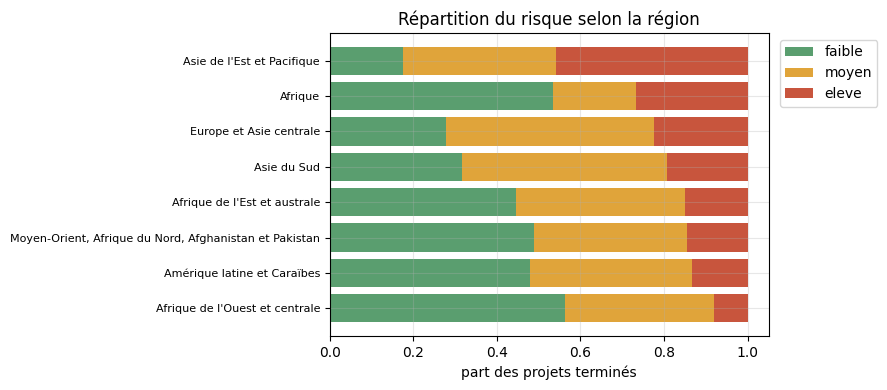

In [17]:
tableau = pd.crosstab(termines["region"], termines["risque"], normalize="index")[ordre_risque]
tableau = tableau.sort_values("eleve")
fig, ax = plt.subplots(figsize=(9, 4))
gauche = np.zeros(len(tableau))
for classe, couleur in zip(ordre_risque, ["#5a9e6f", "#e0a43a", "#c8553d"]):
    ax.barh(tableau.index, tableau[classe], left=gauche, color=couleur, label=classe)
    gauche += tableau[classe].values
ax.set(title="Répartition du risque selon la région", xlabel="part des projets terminés")
ax.tick_params(axis="y", labelsize=8)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
enregistrer("risque_par_region")
plt.show()

La région change beaucoup le risque : près de la moitié des projets d'Asie de l'Est et Pacifique sont à risque élevé, contre moins de 10 % en Afrique de l'Ouest et centrale. C'est l'`effet_region` de la formule. La région sera donc une entrée utile pour le classifieur, alors qu'elle n'apparaît pas dans la formule de la rentabilité (sauf à travers le pays).

## 7. Les 40 anomalies fabriquées

In [18]:
anomalies = pd.read_csv(DONNEES / "anomalies_injectees.csv")
anomalies = anomalies.merge(projets[["id_projet", "statut"]], on="id_projet")
pd.crosstab(anomalies["type_anomalie"], anomalies["statut"], margins=True)

statut,en_cours,termine,All
type_anomalie,,,
cout_aberrant,10,7,17
duree_incoherente,5,8,13
rentabilite_extreme,0,10,10
All,15,25,40


40 projets ont une valeur fabriquée : 25 terminés (donc dans les données d'entraînement possibles) et 15 en cours. Leur détection est le travail du rôle 2, et le fichier `anomalies_injectees.csv` ne doit **jamais** servir d'entrée au modèle. On regarde seulement ici leur effet sur ce que le modèle apprendrait.

In [19]:
ids_anormaux = set(anomalies.loc[anomalies["statut"] == "termine", "id_projet"])
propres = termines[~termines["id_projet"].isin(ids_anormaux)]

comparaison = pd.DataFrame({
    "avec anomalies": [termines["rentabilite"].mean(), termines["rentabilite"].std(),
                       termines["cout_total"].max(), termines["duree_mois"].min(),
                       termines["duree_mois"].corr(termines["rentabilite"])],
    "sans anomalies": [propres["rentabilite"].mean(), propres["rentabilite"].std(),
                       propres["cout_total"].max(), propres["duree_mois"].min(),
                       propres["duree_mois"].corr(propres["rentabilite"])],
}, index=["rentabilité moyenne", "écart-type rentabilité", "coût max", "durée min",
          "corrélation durée-rentabilité"]).round(2)
comparaison

,avec anomalies,sans anomalies
rentabilité moyenne,8.43,8.36
écart-type rentabilité,5.09,3.09
coût max,22000.00,22000.00
durée min,1.00,6.00
corrélation durée-rentabilité,-0.21,-0.36


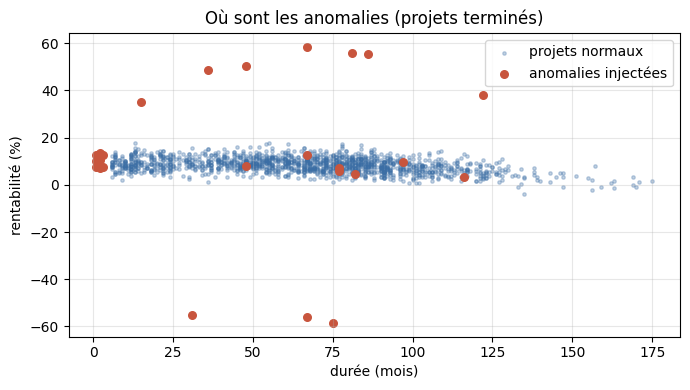

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
normaux_ = termines[~termines["id_projet"].isin(ids_anormaux)]
anormaux_ = termines[termines["id_projet"].isin(ids_anormaux)]
ax.scatter(normaux_["duree_mois"], normaux_["rentabilite"], s=6, alpha=0.3, color="#3b6ea5", label="projets normaux")
ax.scatter(anormaux_["duree_mois"], anormaux_["rentabilite"], s=30, color="#c8553d", label="anomalies injectées")
ax.set(title="Où sont les anomalies (projets terminés)", xlabel="durée (mois)", ylabel="rentabilité (%)")
ax.legend()
enregistrer("anomalies")
plt.show()

Les anomalies sont rares (25 sur 1 500, moins de 2 %) mais très visibles : rentabilités à ±35-60 %, durées de 1 à 3 mois, coûts multipliés par 10 à 50. Elles gonflent fortement l'écart-type de la rentabilité (5,1 points avec elles contre 3,1 sans) et affaiblissent nettement la corrélation durée-rentabilité (−0,21 avec, −0,36 sans). Dans une régression par moindres carrés, quelques points aussi éloignés peuvent tirer les coefficients.

Décision pour la suite (à justifier dans le rapport) : comparer l'entraînement **avec** et **sans** ces projets, sur le jeu d'entraînement seulement. Les retirer est légitime pour l'apprentissage (on ne veut pas apprendre des erreurs de saisie), mais la validation et le test gardent tous les projets, pour mesurer honnêtement le comportement sur des données telles qu'elles arrivent.

## 8. Conséquences pour le prétraitement et la modélisation

| Constat | Décision |
|---|---|
| Cibles connues seulement pour les 1 500 terminés | Apprendre et évaluer sur les terminés ; les 500 en cours ne servent qu'à la prédiction finale |
| Classes de risque 40 / 40 / 20 | Séparation 70 / 15 / 15 **stratifiée** sur le risque ; suivre exactitude **et** F1 macro ; référence = classe majoritaire (40 %) |
| Coût très asymétrique | `log10(cout_total)` puis `StandardScaler` |
| Aucune valeur manquante chez les terminés, mais exigée par le contrat | `SimpleImputer` (médiane pour les nombres, valeur la plus fréquente pour les catégories) |
| 158 pays, beaucoup rares, certains jamais vus | `OneHotEncoder(handle_unknown="ignore")` ; garder aussi la région |
| Courbure de la durée, interaction coût × secteur | Comparer modèles linéaires et modèles à arbres (forêt, boosting) |
| Projets en cours plus récents et plus chers | Limite à écrire : le modèle extrapole en partie |
| 25 anomalies dans les terminés | Tester l'entraînement avec et sans, sur l'entraînement seulement |
| `id_projet`, `nom`, `statut` | Exclus des entrées |

Toutes ces transformations seront **ajustées sur le jeu d'entraînement seulement**, dans un `Pipeline`, après la séparation de la tâche 3.